# Week 7 — Advanced Models for Closing-Price Prediction

This notebook compares XGBoost with the Week 6 Random Forest using the same property and school-district features. The analysis covers light hyperparameter tuning, April test performance, engineered-feature comparisons, complexity controls, and validation feature importance.

**Main finding:** Random Forest achieved the lowest April MAE. Tuned XGBoost achieved lower RMSE and higher R². School districts improved XGBoost validation performance; the additional property features did not.

Settings were initially selected using February and March validation before evaluating April. The later feature and regularization experiments reused those validation months after April had been inspected. Their results are exploratory and require confirmation on a future evaluation period.


## 1. Environment

Dependencies include XGBoost, scikit-learn, pandas, NumPy, GeoPandas, Shapely, and Matplotlib. Package versions are recorded below. The notebook uses the cleaned split export and cached district boundaries from the preceding analysis and runs independently of other notebook kernels.


In [17]:
#importing libraries
import hashlib
import json
import platform
from importlib.metadata import version
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

project_root = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "notebooks" / "02_preprocessing.ipynb").is_file()), None
)
if project_root is None:
    raise FileNotFoundError("Start the kernel in the project root or notebooks directory.")

# Week 3's executable export uses data/raw, despite some narrative paths saying data/.
# Prefer that location; support the documented alternate location if needed.
candidates = [project_root / folder / "cleaned_single_family_sales_with_splits.csv"
              for folder in ("data/raw", "data")]
input_path = next((p for p in candidates if p.is_file()), None)
if input_path is None:
    raise FileNotFoundError("Run the split export in 02_preprocessing.ipynb first.")
print("Input:", input_path.relative_to(project_root))

from sklearn.base import clone
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
import matplotlib.pyplot as plt

import geopandas as gpd
from datetime import datetime, timezone
from sklearn.model_selection import ParameterGrid
from sklearn.metrics import mean_squared_error
from xgboost import XGBRegressor

package_versions = {name: version(name) for name in ["numpy", "pandas", "scikit-learn", "geopandas", "shapely", "xgboost"]}
print("Package versions:", package_versions)


Input: data/cleaned_single_family_sales_with_splits.csv
Package versions: {'numpy': '2.3.5', 'pandas': '2.3.3', 'scikit-learn': '1.7.2', 'geopandas': '1.2.0', 'shapely': '2.2.0', 'xgboost': '3.4.1'}


## 2. Data and evaluation split

The training partition contains **27,974 January–March 2026 sales**; the April test partition contains **12,480 sales**. Validation uses January→February and January–February→March, with no future observations in each training fold.

The checks below verify the saved split and unique listing keys. Sale date determines fold membership and is excluded from predictors. Listing prices, days on market, and sale-derived measurements are also excluded to support the intended off-market prediction task.


In [18]:
# features and target variable for model
NUMERIC_FEATURES = [
    "LivingArea", "LotSizeSquareFeet", "BedroomsTotal", "BathroomsTotalInteger",
    "GarageSpaces", "ParkingTotal", "Stories", "YearBuilt", "Latitude", "Longitude",
]
CATEGORICAL_FEATURES = ["City", "PostalCode"]
TARGET = "ClosePrice"

def sha256_file(path):
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

# PostalCode kept as string for categorical feature
input_sha256 = sha256_file(input_path)
sales = pd.read_csv(input_path, dtype={"ListingKeyNumeric": "string", "PostalCode": "string"})
required = {TARGET, "CloseDate", "ListingKeyNumeric", "split", "selected_training_months"}
missing = required - set(sales.columns)
if missing:
    raise ValueError(f"Required columns missing: {sorted(missing)}")
if not sales["split"].isin(["train", "test", "outside_training_window"]).all():
    raise ValueError("Unexpected or missing split labels; review the Week 3 export.")
sales["CloseDate"] = pd.to_datetime(sales["CloseDate"], errors="raise")
sales[TARGET] = pd.to_numeric(sales[TARGET], errors="raise")
assert sales["CloseDate"].notna().all(), "Missing sale dates."
assert sales["ListingKeyNumeric"].notna().all() and sales["ListingKeyNumeric"].is_unique
assert (np.isfinite(sales[TARGET]) & sales[TARGET].gt(0)).all()

numeric_features = [c for c in NUMERIC_FEATURES if c in sales]
categorical_features = [c for c in CATEGORICAL_FEATURES if c in sales]
for c in numeric_features:
    sales[c] = pd.to_numeric(sales[c], errors="coerce").replace([np.inf, -np.inf], np.nan)
for c in categorical_features:
    sales[c] = sales[c].map(lambda v: str(v).strip() if pd.notna(v) and str(v).strip() else np.nan)

# spliting train/test data
train = sales.loc[sales["split"].eq("train")].copy()
test = sales.loc[sales["split"].eq("test")].copy()
assert len(train) > 0 and len(test) >= 2, "Need training data and at least two test rows."
assert train["CloseDate"].max() < test["CloseDate"].min(), "Split must be chronological."
months = sales["CloseDate"].dt.to_period("M")
test_month = months.max()
assert months.loc[test.index].eq(test_month).all()
assert sales.loc[months.eq(test_month), "split"].eq("test").all()
window_values = pd.to_numeric(sales["selected_training_months"], errors="raise").unique()
assert len(window_values) == 1 and np.isfinite(window_values[0])
window = int(window_values[0])
assert window > 0 and window == window_values[0]
expected_train = months.ge(test_month - window) & months.lt(test_month)
assert sales["split"].eq("train").equals(expected_train), "Split does not match selected window."
assert set(months.loc[train.index]) == set(pd.period_range(test_month - window, test_month - 1, freq="M"))
assert test[TARGET].nunique() > 1, "R² requires a nonconstant test target."

display(sales.groupby("split").agg(
    rows=(TARGET, "size"), first_sale=("CloseDate", "min"), last_sale=("CloseDate", "max")
))
print("Selected training window:", window, "months")


,rows,first_sale,last_sale
split,,,
outside_training_window,20150,2025-11-01,2025-12-31
test,12480,2026-04-01,2026-04-30
train,27974,2026-01-01,2026-03-31


Selected training window: 3 months


## 3. School-district features

The Week 6 boundary snapshot is verified by its content hash and processed with the same geometry-repair and spatial-join rules. All property rows are retained; missing or ambiguous district assignments remain missing.

The model uses **14 predictors**: nine numeric property/location fields, City, PostalCode, and three district codes. ParkingTotal is excluded based on earlier validation. The 2024–25 boundary vintage and cross-type overlaps remain limitations of the geographic layer.


In [19]:
# Load the cached boundary snapshot before attaching district features.
from shapely.validation import make_valid, explain_validity
from shapely.ops import unary_union

def polygonal_district_geometry(geometry):
    """Extract polygon components from make_valid results; never join line remnants."""
    if geometry.geom_type in ("Polygon", "MultiPolygon"):
        return geometry
    if geometry.geom_type == "GeometryCollection":
        parts = [polygonal_district_geometry(part) for part in geometry.geoms]
        polygons = [part for part in parts if part is not None and not part.is_empty]
        return unary_union(polygons) if polygons else None
    return None

def repair_district_geometries(boundaries):
    repaired = boundaries.copy()
    invalid = ~repaired.geometry.is_valid
    audit_rows = []
    for index in repaired.index[invalid]:
        original = repaired.at[index, "geometry"]
        valid_result = make_valid(original)
        polygon_result = polygonal_district_geometry(valid_result)
        audit_rows.append({
            "OBJECTID": repaired.at[index, "OBJECTID"],
            "CDCode": repaired.at[index, "CDCode"],
            "DistrictName": repaired.at[index, "DistrictName"],
            "invalid_reason": explain_validity(original),
            "original_type": original.geom_type,
            "make_valid_type": valid_result.geom_type,
            "polygon_type": None if polygon_result is None else polygon_result.geom_type,
            "nonpolygon_components_removed": valid_result.geom_type not in ("Polygon", "MultiPolygon"),
            "repair_ok": polygon_result is not None and not polygon_result.is_empty and polygon_result.is_valid,
        })
        if polygon_result is not None:
            repaired.at[index, "geometry"] = polygon_result
    audit = pd.DataFrame(audit_rows, columns=[
        "OBJECTID", "CDCode", "DistrictName", "invalid_reason", "original_type",
        "make_valid_type", "polygon_type", "nonpolygon_components_removed", "repair_ok",
    ])
    if len(audit) and not audit["repair_ok"].all():
        display(audit.loc[~audit["repair_ok"]])
        raise ValueError("Some districts could not be repaired as valid polygons; review the rows above.")
    assert repaired.geometry.is_valid.all() and not repaired.geometry.is_empty.any()
    assert repaired.geom_type.isin(["Polygon", "MultiPolygon"]).all()
    assert repaired.index.equals(boundaries.index) and len(repaired) == len(boundaries)
    return repaired, audit

boundary_dir = project_root / "artifacts" / "school_districts_2024_25"
boundary_path = boundary_dir / "boundaries.geojson"
boundary_metadata_path = boundary_dir / "snapshot_metadata.json"
if not boundary_path.exists() or not boundary_metadata_path.exists():
    raise FileNotFoundError("School-district snapshot is missing. Run the Week 6 boundary-loading cell in 04_model_comparison.ipynb first.")
boundary_metadata = json.loads(boundary_metadata_path.read_text())
assert sha256_file(boundary_path) == boundary_metadata["sha256"], "Boundary snapshot hash mismatch."
district_boundaries = gpd.read_file(boundary_path)
assert len(district_boundaries) == boundary_metadata["feature_count"]
required_boundary_fields = {"OBJECTID", "CDCode", "DistrictName", "DistrictType", "Year"}
assert required_boundary_fields.issubset(district_boundaries.columns), "Boundary fields are missing."
assert district_boundaries.crs is not None, "Boundary CRS is missing."
assert district_boundaries.geometry.notna().all() and not district_boundaries.geometry.is_empty.any()
district_boundaries = district_boundaries.to_crs("EPSG:4326")
district_boundaries, geometry_audit = repair_district_geometries(district_boundaries)
for column in ["CDCode", "DistrictType"]:
    district_boundaries[column] = district_boundaries[column].astype("string").str.strip()
    assert district_boundaries[column].notna().all() and district_boundaries[column].ne("").all()
assert set(district_boundaries["Year"].dropna().astype(str)) == {"2024-25"}
print("Boundary records:", len(district_boundaries), "Repaired:", len(geometry_audit))


Boundary records: 937 Repaired: 7


In [20]:
def attach_school_districts(frame, district_boundaries):
    # Classify source types explicitly; stop if the source introduces an unfamiliar type.
    def district_type_group(value):
        value = str(value).strip().lower()
        if "unified" in value:
            return "Unified"
        if "elementary" in value:
            return "Elementary"
        if "high" in value:
            return "High"
        raise ValueError(f"Unrecognized DistrictType: {value!r}; inspect source types before joining.")
    
    district_boundaries["district_group"] = district_boundaries["DistrictType"].map(district_type_group)
    assert set(district_boundaries["district_group"]) == {"Elementary", "High", "Unified"}
    
    # Longitude is x; latitude is y. A global range check does not establish CA membership.
    assert frame.index.is_unique
    coordinate_ok = (
        frame["Longitude"].between(-180, 180)
        & frame["Latitude"].between(-90, 90)
        & np.isfinite(frame["Longitude"])
        & np.isfinite(frame["Latitude"])
    )
    district_points = gpd.GeoDataFrame(
        index=frame.index[coordinate_ok],
        geometry=gpd.points_from_xy(frame.loc[coordinate_ok, "Longitude"],
                                   frame.loc[coordinate_ok, "Latitude"]),
        crs="EPSG:4326",
    )
    enriched = frame.copy()
    district_join_audit = pd.DataFrame(index=frame.index)
    district_join_audit["coordinate_status"] = np.where(coordinate_ok, "available", "missing_or_invalid")
    DISTRICT_FEATURES = []
    district_ambiguous_candidates = {}
    for district_group in ["Elementary", "High", "Unified"]:
        column = f"{district_group}DistrictCode"
        DISTRICT_FEATURES.append(column)
        polygons = district_boundaries.loc[
            district_boundaries["district_group"].eq(district_group), ["CDCode", "geometry"]
        ]
        matches = gpd.sjoin(district_points, polygons, how="left", predicate="intersects")
        matched = matches.loc[matches["CDCode"].notna(), ["CDCode"]]
        candidates = matched.groupby(level=0)["CDCode"].agg(lambda x: sorted(set(x)))
        counts = candidates.map(len).reindex(frame.index, fill_value=0)
        unique_matches = candidates.loc[candidates.map(len).eq(1)].map(lambda x: x[0])
        # Object dtype with np.nan is compatible with the existing categorical imputer.
        enriched[column] = unique_matches.reindex(frame.index).astype(object)
        enriched[column] = enriched[column].where(enriched[column].notna(), np.nan)
        district_join_audit[f"{district_group}_match_count"] = counts
        district_join_audit[f"{district_group}_status"] = np.select(
            [~coordinate_ok, counts.gt(1), counts.eq(1)],
            ["missing_or_invalid_coordinates", "ambiguous", "matched"], default="no_match"
        )
        district_ambiguous_candidates[district_group] = candidates.loc[candidates.map(len).gt(1)]
        assert enriched.loc[counts.ne(1), column].isna().all()
    assert enriched.index.equals(frame.index)
    assert len(enriched) == len(frame)
    print("Property rows preserved:", len(enriched))
    return enriched, district_join_audit

train_geo, train_district_audit = attach_school_districts(train, district_boundaries.copy())
DISTRICT_FEATURES = ["ElementaryDistrictCode", "HighDistrictCode", "UnifiedDistrictCode"]
NUMERIC_USED = [c for c in NUMERIC_FEATURES if c != "ParkingTotal"]
CATEGORICAL_USED = CATEGORICAL_FEATURES + DISTRICT_FEATURES
FEATURES = NUMERIC_USED + CATEGORICAL_USED
assert set(FEATURES).issubset(train_geo.columns)
assert len(FEATURES) == 14
print("Frozen feature set:", FEATURES)
print("Train assigned any district:", train_geo[DISTRICT_FEATURES].notna().any(axis=1).mean())


Property rows preserved: 27974
Frozen feature set: ['LivingArea', 'LotSizeSquareFeet', 'BedroomsTotal', 'BathroomsTotalInteger', 'GarageSpaces', 'Stories', 'YearBuilt', 'Latitude', 'Longitude', 'City', 'PostalCode', 'ElementaryDistrictCode', 'HighDistrictCode', 'UnifiedDistrictCode']
Train assigned any district: 0.9950311003074284


## 4. Model setup

Random Forest and XGBoost use identical features and preprocessing. Numeric imputation, missing indicators, scaling, and categorical encoding are fitted within each training fold. Scaling is retained for consistency. Unseen categories receive no learned category-specific effect, as reported by the encoder warnings.

The XGBoost grid contains eight combinations: depths **3/6**, learning rates **0.03/0.1**, and **200/500 trees**. The starter configuration uses depth 3, learning rate 0.1, and 200 trees. The target remains closing price in dollars, with squared-error training loss. Mean monthly validation MAE determines parameter selection; RMSE and R² provide additional context.


In [21]:
def build_pipeline(estimator, training_rows):
    numeric = [c for c in NUMERIC_USED if training_rows[c].notna().any()]
    categorical = [c for c in CATEGORICAL_USED if training_rows[c].notna().any()]
    transforms = []
    if numeric:
        transforms.append(("numeric", Pipeline([
            ("impute", SimpleImputer(strategy="median", add_indicator=True)),
            ("scale", StandardScaler()),
        ]), numeric))
    if categorical:
        transforms.append(("categorical", Pipeline([
            ("impute", SimpleImputer(strategy="constant", fill_value="Missing")),
            ("encode", OneHotEncoder(handle_unknown="ignore", drop="first")),
        ]), categorical))
    return Pipeline([("preprocess", ColumnTransformer(transforms)), ("regression", clone(estimator))])

def regression_metrics(actual, predicted):
    assert np.isfinite(predicted).all()
    return {"mae_usd": mean_absolute_error(actual, predicted),
            "rmse_usd": float(np.sqrt(mean_squared_error(actual, predicted))),
            "r2": r2_score(actual, predicted)}

XGB_FIXED = dict(objective="reg:squarederror", tree_method="hist", random_state=42, n_jobs=4)
STARTER_PARAMS = dict(max_depth=3, learning_rate=0.1, n_estimators=200)
TUNING_GRID = dict(max_depth=[3, 6], learning_rate=[0.03, 0.1], n_estimators=[200, 500])
CANDIDATES = list(ParameterGrid(TUNING_GRID))
fold_months = train_geo["CloseDate"].dt.to_period("M")
available_months = sorted(fold_months.unique())
assert len(available_months) == 3 and available_months == list(pd.period_range(available_months[0], available_months[-1], freq="M"))
VALIDATION_MONTHS = available_months[-2:]
display(pd.DataFrame(CANDIDATES))


,learning_rate,max_depth,n_estimators
0,0.03,3,200
1,0.03,3,500
2,0.03,6,200
3,0.03,6,500
4,0.10,3,200
5,0.10,3,500
6,0.10,6,200
7,0.10,6,500


## 5. Hyperparameter tuning

Configurations are ranked by equal-weight mean MAE across February and March validation. Fewer trees and shallower depth break exact ties. April is excluded from this selection.


In [22]:
tuning_rows = []
for candidate_id, parameters in enumerate(CANDIDATES):
    print(f"Candidate {candidate_id + 1}/{len(CANDIDATES)}: {parameters}", flush=True)
    for validation_month in VALIDATION_MONTHS:
        fit_rows = train_geo.loc[fold_months.lt(validation_month)]
        valid_rows = train_geo.loc[fold_months.eq(validation_month)]
        assert fit_rows["CloseDate"].max() < valid_rows["CloseDate"].min()
        assert len(valid_rows) >= 2 and valid_rows[TARGET].nunique() > 1
        model = build_pipeline(XGBRegressor(**XGB_FIXED, **parameters), fit_rows)
        model.fit(fit_rows[FEATURES], fit_rows[TARGET])
        predicted = model.predict(valid_rows[FEATURES])
        training_r2 = r2_score(fit_rows[TARGET], model.predict(fit_rows[FEATURES]))
        metrics = regression_metrics(valid_rows[TARGET], predicted)
        tuning_rows.append({"candidate_id": candidate_id, "validation_month": str(validation_month),
                            **parameters, **metrics, "train_r2": training_r2,
                            "r2_gap": training_r2 - metrics["r2"],
                            "train_rows": len(fit_rows), "validation_rows": len(valid_rows)})
tuning_results = pd.DataFrame(tuning_rows)
tuning_summary = tuning_results.groupby(
    ["candidate_id", "max_depth", "learning_rate", "n_estimators"], as_index=False
).agg(mean_monthly_mae_usd=("mae_usd", "mean"), mean_monthly_rmse_usd=("rmse_usd", "mean"),
      mean_monthly_r2=("r2", "mean"), mean_r2_gap=("r2_gap", "mean"))
tuning_summary = tuning_summary.sort_values(
    ["mean_monthly_mae_usd", "n_estimators", "max_depth", "learning_rate"]
).reset_index(drop=True)
best_candidate_id = int(tuning_summary.iloc[0]["candidate_id"])
BEST_PARAMS = dict(CANDIDATES[best_candidate_id])
display(tuning_results.round(4))
display(tuning_summary.round(4))
print("Validation-selected parameters:", BEST_PARAMS)


Candidate 1/8: {'learning_rate': 0.03, 'max_depth': 3, 'n_estimators': 200}


/opt/anaconda3/envs/myenv/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 1, 2, 3, 4] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


Candidate 2/8: {'learning_rate': 0.03, 'max_depth': 3, 'n_estimators': 500}


/opt/anaconda3/envs/myenv/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 1, 2, 3, 4] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/opt/anaconda3/envs/myenv/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 1, 2, 3, 4] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


Candidate 3/8: {'learning_rate': 0.03, 'max_depth': 6, 'n_estimators': 200}


/opt/anaconda3/envs/myenv/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 1, 2, 3, 4] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/opt/anaconda3/envs/myenv/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 1, 2, 3, 4] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


... (9 outputs left out)

/opt/anaconda3/envs/myenv/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 1, 2, 3, 4] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/opt/anaconda3/envs/myenv/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 1, 2, 3, 4] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/opt/anaconda3/envs/myenv/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 1, 2, 3, 4] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


,candidate_id,validation_month,learning_rate,max_depth,n_estimators,mae_usd,rmse_usd,r2,train_r2,r2_gap,train_rows,validation_rows
0,0,2026-02,0.03,3,200,385889.0355,850338.6131,0.5912,0.7760,0.1847,7473,8950
1,0,2026-03,0.03,3,200,389207.9963,863466.9616,0.6565,0.7258,0.0693,16423,11551
2,1,2026-02,0.03,3,500,340888.9743,793851.5065,0.6437,0.8467,0.2030,7473,8950
3,1,2026-03,0.03,3,500,332846.5618,783702.0886,0.7170,0.8099,0.0929,16423,11551
4,2,2026-02,0.03,6,200,314731.2565,778277.5678,0.6576,0.9161,0.2585,7473,8950
5,2,2026-03,0.03,6,200,303072.6649,736083.4426,0.7504,0.8840,0.1336,16423,11551
6,3,2026-02,0.03,6,500,286113.3480,749370.8806,0.6825,0.9475,0.2649,7473,8950
7,3,2026-03,0.03,6,500,272818.3809,696467.9890,0.7765,0.9213,0.1447,16423,11551
8,4,2026-02,0.10,3,200,327983.0944,776948.0091,0.6588,0.8646,0.2058,7473,8950
9,4,2026-03,0.10,3,200,316259.9833,761468.7680,0.7329,0.8331,0.1003,16423,11551


,candidate_id,max_depth,learning_rate,n_estimators,mean_monthly_mae_usd,mean_monthly_rmse_usd,mean_monthly_r2,mean_r2_gap
0,7,6,0.10,500,251402.7000,701799.1102,0.7446,0.2256
1,6,6,0.10,200,274343.1186,720066.7111,0.7316,0.2118
2,3,6,0.03,500,279465.8644,722919.4348,0.7295,0.2048
3,5,3,0.10,500,288313.1476,731323.7130,0.7246,0.1763
4,2,6,0.03,200,308901.9607,757180.5052,0.7040,0.1961
5,4,3,0.10,200,322121.5388,769208.3885,0.6958,0.1531
6,1,3,0.03,500,336867.7681,788776.7975,0.6804,0.1479
7,0,3,0.03,200,387548.5159,856902.7874,0.6239,0.1270


Validation-selected parameters: {'learning_rate': 0.1, 'max_depth': 6, 'n_estimators': 500}


### Tuning results

**Depth 6, learning rate 0.1, and 500 trees** produced the lowest MAE in both validation months. Mean monthly MAE decreased from **$322,122 to $251,403**, a **22.0%** improvement over the starter.

The selected configuration retained a mean training–validation R² gap of **0.2256**. It also uses the largest values in the tested grid, so the result identifies the best tested configuration rather than an overall optimum.


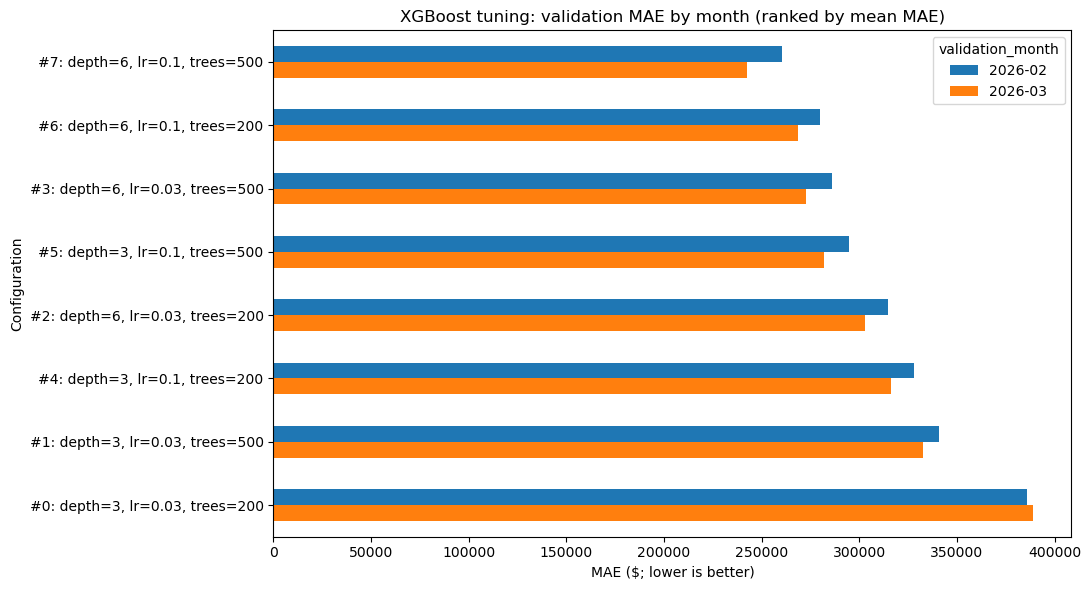

In [23]:
# Display each month rather than hiding instability behind the mean.
validation_chart = tuning_results.pivot(index="candidate_id", columns="validation_month", values="mae_usd")
ordered_ids = tuning_summary["candidate_id"].tolist()
validation_chart = validation_chart.reindex(ordered_ids)
validation_chart.index = [
    f"#{candidate_id}: depth={CANDIDATES[candidate_id]['max_depth']}, "
    f"lr={CANDIDATES[candidate_id]['learning_rate']}, trees={CANDIDATES[candidate_id]['n_estimators']}"
    for candidate_id in ordered_ids
]
ax = validation_chart.plot.barh(figsize=(11, 6))
ax.invert_yaxis()
ax.set(title="XGBoost tuning: validation MAE by month (ranked by mean MAE)",
       xlabel="MAE ($; lower is better)", ylabel="Configuration")
plt.tight_layout()
plt.show()


## 6. April test comparison

The starter XGBoost, tuned XGBoost, and 100-tree Random Forest are fitted on all January–March sales and evaluated on identical April properties. Random Forest is refitted with the district-enhanced features rather than assigned a score from the earlier Week 5 feature set.

April was inspected in preceding analyses. These results are therefore a historical test comparison, and no subsequent tuning uses April scores.


In [24]:
test_geo, test_district_audit = attach_school_districts(test, district_boundaries.copy())
assert test_geo.index.equals(test.index) and len(test_geo) == len(test)
assert train_geo["CloseDate"].max() < test_geo["CloseDate"].min()
final_estimators = {
    "Random Forest: Week 6 features": RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=4),
    "XGBoost: starter": XGBRegressor(**XGB_FIXED, **STARTER_PARAMS),
    "XGBoost: validation-selected": XGBRegressor(**XGB_FIXED, **BEST_PARAMS),
}
final_models, test_predictions, metric_rows = {}, {}, []
for name, estimator in final_estimators.items():
    print("Refitting:", name, flush=True)
    fitted_model = build_pipeline(estimator, train_geo)
    fitted_model.fit(train_geo[FEATURES], train_geo[TARGET])
    training_metrics = regression_metrics(train_geo[TARGET], fitted_model.predict(train_geo[FEATURES]))
    predicted = fitted_model.predict(test_geo[FEATURES])
    metrics = regression_metrics(test_geo[TARGET], predicted)
    final_models[name] = fitted_model
    test_predictions[name] = predicted
    metric_rows.append({"model": name, "train_rows": len(train_geo), "test_rows": len(test_geo),
                        "train_r2": training_metrics["r2"], "test_r2": metrics["r2"],
                        "test_mae_usd": metrics["mae_usd"], "test_rmse_usd": metrics["rmse_usd"],
                        "r2_gap": training_metrics["r2"] - metrics["r2"]})
test_metrics = pd.DataFrame(metric_rows).set_index("model")
rf_mae = test_metrics.loc["Random Forest: Week 6 features", "test_mae_usd"]
test_metrics["mae_improvement_usd_vs_forest"] = rf_mae - test_metrics["test_mae_usd"]
test_metrics["mae_improvement_pct_vs_forest"] = 100 * test_metrics["mae_improvement_usd_vs_forest"] / rf_mae
display(test_metrics.round(4))
print("Starter equals selected parameters:", STARTER_PARAMS == BEST_PARAMS)
print("All metrics above use the same historical test month:", str(test_month))


Property rows preserved: 12480
Refitting: Random Forest: Week 6 features
Refitting: XGBoost: starter


/opt/anaconda3/envs/myenv/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 1, 2, 3, 4] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


Refitting: XGBoost: validation-selected


/opt/anaconda3/envs/myenv/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 1, 2, 3, 4] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/opt/anaconda3/envs/myenv/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 1, 2, 3, 4] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


,train_rows,test_rows,train_r2,test_r2,test_mae_usd,test_rmse_usd,r2_gap,mae_improvement_usd_vs_forest,mae_improvement_pct_vs_forest
model,,,,,,,,,
Random Forest: Week 6 features,27974,12480,0.9669,0.6962,241294.6381,859906.9641,0.2707,0.0000,0.0000
XGBoost: starter,27974,12480,0.8293,0.6829,327353.1294,878503.6641,0.1464,-86058.4913,-35.6653
XGBoost: validation-selected,27974,12480,0.9574,0.7292,251189.0882,811824.7092,0.2282,-9894.4501,-4.1006


Starter equals selected parameters: False
All metrics above use the same historical test month: 2026-04


### Week 8 handoff — save the fixed April predictions

This cell saves the original April predictions for `06_evaluation.ipynb` without fitting another model. Run this notebook from the top through the April comparison above, then run the export below. The later diagnostic, feature, and regularization sections are not required for this handoff.

The files under `artifacts/week7/` contain actual prices, aligned predictions, listing keys, sale dates, and provenance. Week 8 uses them to calculate percentage errors and aggregate price-band metrics.


In [25]:
# Export exactly the original April comparison, not the later validation experiments.
required_handoff_variables = ["project_root", "test_geo", "test_predictions", "test_metrics",
                              "TARGET", "test_month", "FEATURES", "BEST_PARAMS", "input_sha256",
                              "package_versions", "boundary_metadata", "regression_metrics", "sha256_file"]
missing_handoff_variables = [name for name in required_handoff_variables if name not in globals()]
if missing_handoff_variables:
    raise RuntimeError("Run Week 7 from the top through the April comparison before this handoff. Missing: "
                       + ", ".join(missing_handoff_variables))
week8_handoff_dir = project_root / "artifacts" / "week7"
week8_handoff_dir.mkdir(parents=True, exist_ok=True)
week8_model_names = list(test_predictions)
week8_actual = test_geo[TARGET].to_numpy(dtype=float)
week8_predictions = np.column_stack([np.asarray(test_predictions[name], dtype=float) for name in week8_model_names])
assert week8_predictions.shape == (len(test_geo), len(week8_model_names))
assert np.isfinite(week8_actual).all() and (week8_actual > 0).all()
assert np.isfinite(week8_predictions).all()
assert test_geo["ListingKeyNumeric"].notna().all() and test_geo["ListingKeyNumeric"].is_unique
assert test_geo["CloseDate"].dt.to_period("M").eq(test_month).all()
# Catch predictions changed in memory since the saved comparison was computed.
for column, name in enumerate(week8_model_names):
    calculated = regression_metrics(week8_actual, week8_predictions[:, column])
    expected = test_metrics.loc[name]
    assert np.allclose([calculated["mae_usd"], calculated["rmse_usd"], calculated["r2"]],
                       [expected["test_mae_usd"], expected["test_rmse_usd"], expected["test_r2"]],
                       rtol=1e-8, atol=1e-6), f"Prediction/metric mismatch: {name}"
week8_bundle_path = week8_handoff_dir / "april_evaluation_predictions.npz"
np.savez_compressed(
    week8_bundle_path, actual=week8_actual, predictions=week8_predictions,
    model_names=np.asarray(week8_model_names, dtype=str),
    listing_keys=test_geo["ListingKeyNumeric"].astype(str).to_numpy(dtype=str),
    sale_dates=test_geo["CloseDate"].dt.strftime("%Y-%m-%d").to_numpy(dtype=str),
)
week8_manifest = {
    "created_utc": datetime.now(timezone.utc).isoformat(), "test_month": str(test_month),
    "rows": len(test_geo), "model_names": week8_model_names,
    "bundle_sha256": sha256_file(week8_bundle_path), "input_sha256": input_sha256,
    "features": FEATURES, "selected_xgboost_parameters": BEST_PARAMS,
    "package_versions": package_versions, "boundary_sha256": boundary_metadata["sha256"],
    "reference_test_metrics": json.loads(test_metrics.reset_index().to_json(orient="records")),
    "evaluation_note": "Original Week 7 April comparison; historical test month previously inspected; no retuning in Week 8.",
}
(week8_handoff_dir / "april_evaluation_manifest.json").write_text(json.dumps(week8_manifest, indent=2) + "\n")
print("Saved fixed predictions:", week8_bundle_path)
print("Saved evaluation manifest:", week8_handoff_dir / "april_evaluation_manifest.json")


Saved fixed predictions: /Users/daira/IDX-Exchange-Data-Science/artifacts/week7/april_evaluation_predictions.npz
Saved evaluation manifest: /Users/daira/IDX-Exchange-Data-Science/artifacts/week7/april_evaluation_manifest.json


### Test results

| Model | MAE | RMSE | R² |
| --- | ---: | ---: | ---: |
| Random Forest | **$241,295** | $859,907 | 0.6962 |
| Starter XGBoost | $327,353 | $878,504 | 0.6829 |
| Tuned XGBoost | $251,189 | **$811,825** | **0.7292** |

Tuning reduced XGBoost MAE by **$76,164 (23.3%)** relative to the starter. Compared with Random Forest, tuned XGBoost had **$9,894 higher MAE (4.10%)** but **$48,082 lower RMSE (5.59%)**.

Random Forest remains preferable for the primary MAE objective. XGBoost performs better on squared error, which gives greater weight to large misses. On identical test observations, lower RMSE and higher R² reflect the same squared-error improvement. Residual and price-band diagnostics examine how these differences are distributed.


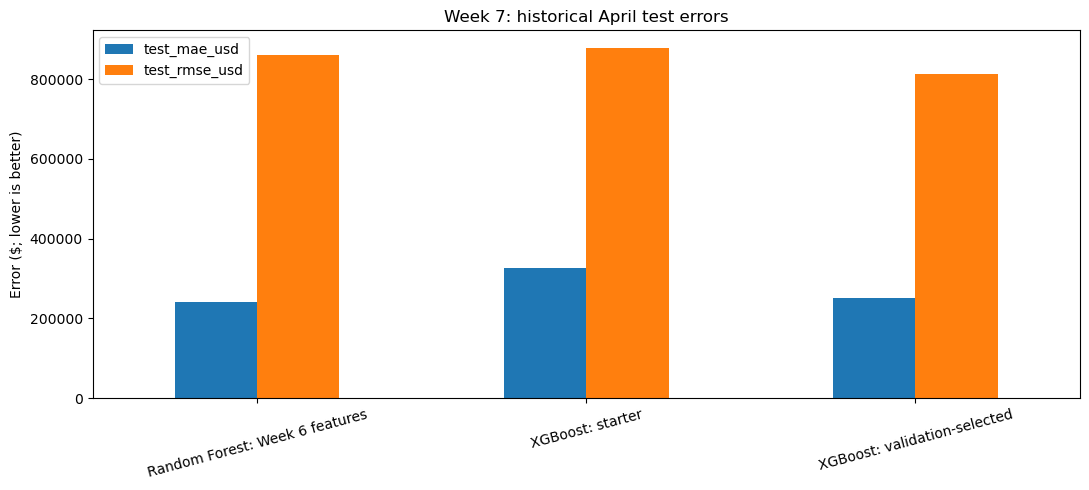

Selected XGBoost: MAE $251,189.09; RMSE $811,824.71; R² 0.7292.
MAE improvement versus same-feature Random Forest: $-9,894.45 (positive is better).
Saved: /Users/daira/IDX-Exchange-Data-Science/artifacts/week7/advanced_model_results.json


In [26]:
ax = test_metrics[["test_mae_usd", "test_rmse_usd"]].plot.bar(figsize=(11, 5), rot=15)
ax.set(title="Week 7: historical April test errors", ylabel="Error ($; lower is better)", xlabel="")
plt.tight_layout()
plt.show()
selected = test_metrics.loc["XGBoost: validation-selected"]
print(f"Selected XGBoost: MAE ${selected['test_mae_usd']:,.2f}; RMSE ${selected['test_rmse_usd']:,.2f}; R² {selected['test_r2']:.4f}.")
print(f"MAE improvement versus same-feature Random Forest: ${selected['mae_improvement_usd_vs_forest']:,.2f} (positive is better).")
output_dir = project_root / "artifacts" / "week7"
output_dir.mkdir(parents=True, exist_ok=True)
report = {
    "generated_utc": datetime.now(timezone.utc).isoformat(),
    "input_sha256": input_sha256, "boundary_snapshot": boundary_metadata,
    "package_versions": package_versions, "features": FEATURES,
    "fixed_xgboost_parameters": XGB_FIXED, "grid": TUNING_GRID,
    "starter_parameters": STARTER_PARAMS, "selected_parameters": BEST_PARAMS,
    "selection_metric": "equal-month February/March validation MAE",
    "validation_results": json.loads(tuning_results.to_json(orient="records")),
    "validation_summary": json.loads(tuning_summary.to_json(orient="records")),
    "test_metrics": json.loads(test_metrics.reset_index().to_json(orient="records")),
    "test_month": str(test_month),
    "limitations": ["April previously inspected; historical test comparison, not a newly untouched estimate.",
                    "Repeated historical validation selection and 2024-25 geography limitations carry forward from Week 6."],
}
(output_dir / "advanced_model_results.json").write_text(json.dumps(report, indent=2) + "\n")
print("Saved:", output_dir / "advanced_model_results.json")


## 7. Prediction-error diagnostics

The following diagnostics compare actual and predicted prices, residuals, and errors by price band. Band thresholds are the training median and 90th percentile. A positive residual indicates underprediction.

Scatterplots use a reproducible sample for readability. Nonpositive predictions are counted and retained in all metrics; only positive values appear on logarithmic price axes. Median errors and a training-median benchmark supplement the mean metrics. These diagnostics describe the fitted models without changing their settings.


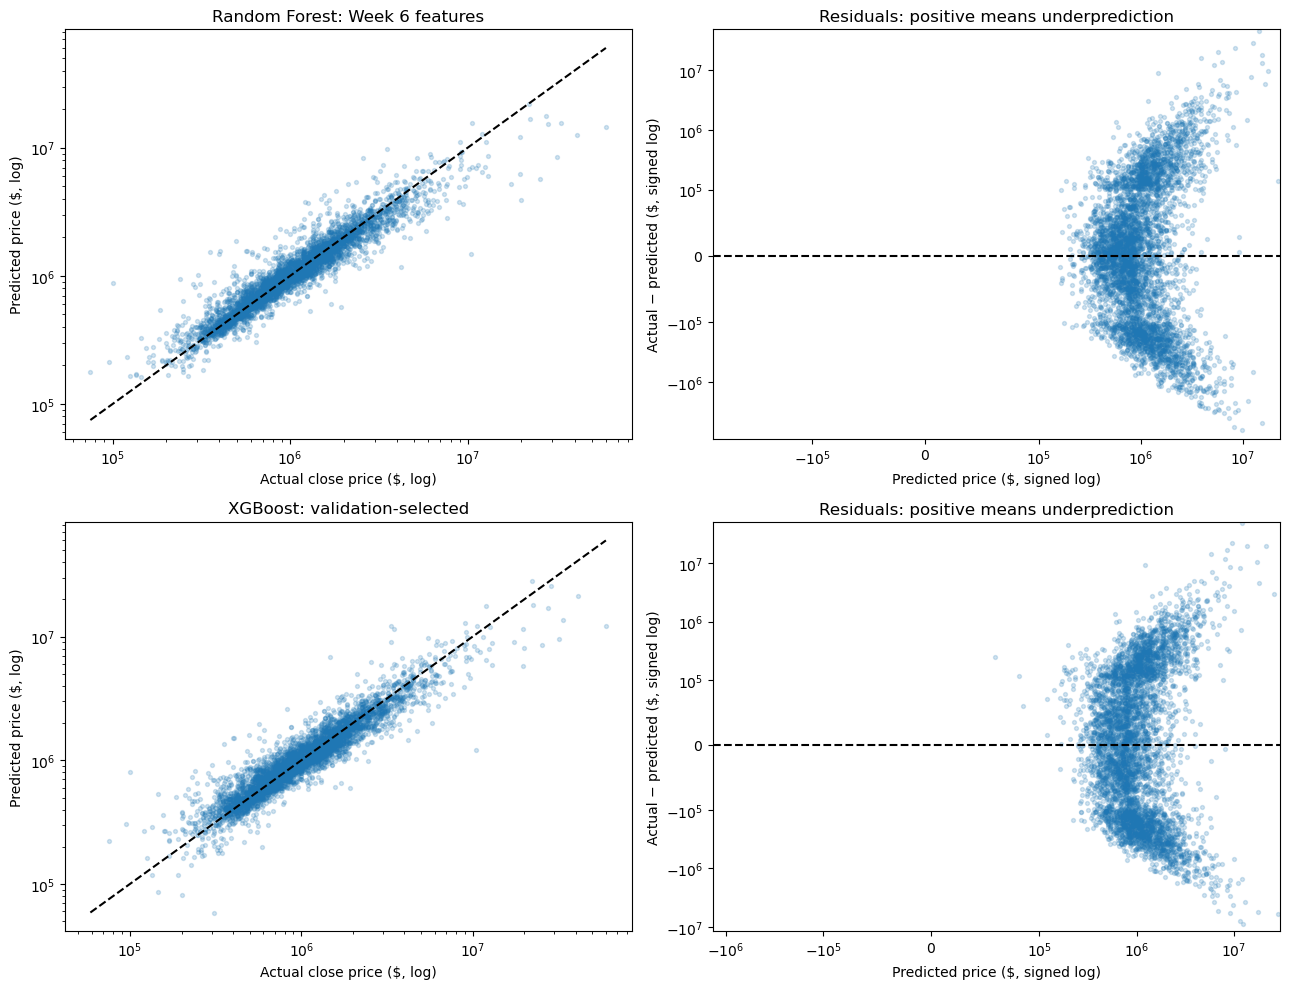

Price-band boundaries from training data: [ 875000. 2300000.]


,model,median_absolute_error_usd,p90_absolute_error_usd,median_absolute_percentage_error_pct,mean_residual_usd,nonpositive_predictions
0,Random Forest: Week 6 features,85050.66,493922.82,9.23,41269.91,0
1,XGBoost: validation-selected,112044.97,502513.72,12.28,25893.03,1


,model,price_band,rows,mae_usd,rmse_usd,r2,mean_residual_usd
0,Random Forest: Week 6 features,At/below training median,5890,8.013402e+04,1.552141e+05,0.2104,-39367.5111
1,Random Forest: Week 6 features,Training median to P90,5239,2.062703e+05,3.492503e+05,0.1398,-22177.1389
2,Random Forest: Week 6 features,Above training P90,1351,1.079732e+06,2.500523e+06,0.4531,638866.8461
3,XGBoost: validation-selected,At/below training median,5890,1.050389e+05,1.672123e+05,0.0836,-53613.8515
4,XGBoost: validation-selected,Training median to P90,5239,2.214535e+05,3.612090e+05,0.0798,-8282.4213
5,XGBoost: validation-selected,Above training P90,1351,1.003675e+06,2.336724e+06,0.5224,505049.7840


Training-median reference on April: {'mae_usd': 693133.941292468, 'rmse_usd': 1619442.4580374998, 'r2': -0.07759622289950174}


In [27]:
diagnostic_models = ["Random Forest: Week 6 features", "XGBoost: validation-selected"]
actual = test_geo[TARGET].to_numpy(dtype=float)
sample_positions = np.random.default_rng(42).choice(len(actual), size=min(5000, len(actual)), replace=False)
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
price_cuts = train_geo[TARGET].quantile([.5, .9]).to_numpy(dtype=float)
assert price_cuts[0] < price_cuts[1]
price_bands = pd.cut(actual, bins=[-np.inf, *price_cuts, np.inf],
                     labels=["At/below training median", "Training median to P90", "Above training P90"])
diagnostic_rows, band_rows = [], []
for row, model_name in enumerate(diagnostic_models):
    prediction = np.asarray(test_predictions[model_name], dtype=float)
    assert len(prediction) == len(actual) and np.isfinite(prediction).all()
    residual = actual - prediction
    absolute = np.abs(residual)
    diagnostic_rows.append({
        "model": model_name, "median_absolute_error_usd": np.median(absolute),
        "p90_absolute_error_usd": np.quantile(absolute, .9),
        "median_absolute_percentage_error_pct": np.median(100 * absolute / actual),
        "mean_residual_usd": residual.mean(), "nonpositive_predictions": int((prediction <= 0).sum()),
    })
    positive = sample_positions[prediction[sample_positions] > 0]
    ax = axes[row, 0]
    ax.scatter(actual[positive], prediction[positive], s=8, alpha=.2)
    if len(positive):
        low = min(actual[positive].min(), prediction[positive].min())
        high = max(actual[positive].max(), prediction[positive].max())
        ax.plot([low, high], [low, high], color="black", linestyle="--")
    ax.set(xscale="log", yscale="log", title=model_name,
           xlabel="Actual close price ($, log)", ylabel="Predicted price ($, log)")
    ax = axes[row, 1]
    ax.scatter(prediction[sample_positions], residual[sample_positions], s=8, alpha=.2)
    ax.axhline(0, color="black", linestyle="--")
    ax.set_xscale("symlog", linthresh=100000)
    ax.set_yscale("symlog", linthresh=100000)
    ax.set(title="Residuals: positive means underprediction", xlabel="Predicted price ($, signed log)",
           ylabel="Actual − predicted ($, signed log)")
    band_frame = pd.DataFrame({"price_band": price_bands, "actual": actual,
                                "prediction": prediction, "residual": residual})
    for band, group in band_frame.groupby("price_band", observed=True):
        band_rows.append({"model": model_name, "price_band": str(band), "rows": len(group),
                          **regression_metrics(group["actual"], group["prediction"]),
                          "mean_residual_usd": group["residual"].mean()})
fig.tight_layout()
plt.show()
error_diagnostics = pd.DataFrame(diagnostic_rows)
price_band_metrics = pd.DataFrame(band_rows)
print("Price-band boundaries from training data:", price_cuts)
display(error_diagnostics.round(2))
display(price_band_metrics.round(4))

# Reference with no property inputs: predict the training median for every test sale.
median_reference_metrics = regression_metrics(actual, np.full(len(actual), train_geo[TARGET].median()))
print("Training-median reference on April:", median_reference_metrics)


## 8. Engineered-feature comparison

The XGBoost feature experiments hold selected settings and validation rows fixed while comparing properties alone, properties plus districts, and additions of logs, ratios, and the full engineered bundle.

The bundle contains log living area, log lot size, bed/bath ratio, living area per bedroom, and property age. Undefined ratios remain missing. PropertyAge uses the historical reference year and duplicates YearBuilt within these 2026 folds. ParkingTotal is excluded throughout.

This experiment was conducted after the April comparison and reuses February/March validation. The original April scores remain attached to their original models; the additional feature choices have no independent test confirmation.


,feature_set,predictor_count,predictors
0,Properties only,11,"LivingArea, LotSizeSquareFeet, BedroomsTotal, ..."
1,Properties + districts,14,"LivingArea, LotSizeSquareFeet, BedroomsTotal, ..."
2,Geo + logs,16,"LivingArea, LotSizeSquareFeet, BedroomsTotal, ..."
3,Geo + ratios,16,"LivingArea, LotSizeSquareFeet, BedroomsTotal, ..."
4,Geo + all engineered,19,"LivingArea, LotSizeSquareFeet, BedroomsTotal, ..."


Feature study 2026-02: Properties only
Feature study 2026-02: Properties + districts


/opt/anaconda3/envs/myenv/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


Feature study 2026-02: Geo + logs


/opt/anaconda3/envs/myenv/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 1, 2, 3, 4] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


Feature study 2026-02: Geo + ratios


... (12 outputs left out)

/opt/anaconda3/envs/myenv/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 1, 2, 3, 4] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/opt/anaconda3/envs/myenv/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 1, 2, 3, 4] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


,validation_month,feature_set,train_mae_usd,train_r2,validation_mae_usd,validation_rmse_usd,validation_r2,r2_gap,train_rows,validation_rows
0,2026-02,Properties only,139829.8532,0.9760,265136.3993,756732.4145,0.6763,0.2997,7473,8950
1,2026-02,Properties + districts,132632.0677,0.9781,260507.7995,732859.9520,0.6964,0.2818,7473,8950
2,2026-02,Geo + logs,132632.0677,0.9781,260507.7995,732859.9520,0.6964,0.2818,7473,8950
3,2026-02,Geo + ratios,128009.8797,0.9807,262138.5717,756540.0283,0.6764,0.3043,7473,8950
4,2026-02,Geo + all engineered,128009.8797,0.9807,262138.5717,756540.0283,0.6764,0.3043,7473,8950
5,2026-03,Properties only,165216.2722,0.9568,248201.1492,677843.4835,0.7883,0.1685,16423,11551
6,2026-03,Properties + districts,155782.4344,0.9621,242297.6004,670738.2684,0.7927,0.1694,16423,11551
7,2026-03,Geo + logs,155782.4344,0.9621,242297.6004,670738.2684,0.7927,0.1694,16423,11551
8,2026-03,Geo + ratios,149980.2572,0.9642,243128.4821,688017.3574,0.7819,0.1823,16423,11551
9,2026-03,Geo + all engineered,149980.2572,0.9642,243128.4821,688017.3574,0.7819,0.1823,16423,11551


,mean_validation_mae_usd,mean_validation_rmse_usd,mean_validation_r2,mean_train_r2,mean_r2_gap,mae_improvement_vs_geo_reference_usd
feature_set,,,,,,
Properties + districts,251402.7000,701799.1102,0.7446,0.9701,0.2256,0.0000
Geo + logs,251402.7000,701799.1102,0.7446,0.9701,0.2256,0.0000
Geo + ratios,252633.5269,722278.6928,0.7292,0.9725,0.2433,-1230.8269
Geo + all engineered,252633.5269,722278.6928,0.7292,0.9725,0.2433,-1230.8269
Properties only,256668.7742,717287.9490,0.7323,0.9664,0.2341,-5266.0743


Provisional feature candidate (reused validation only): Properties + districts


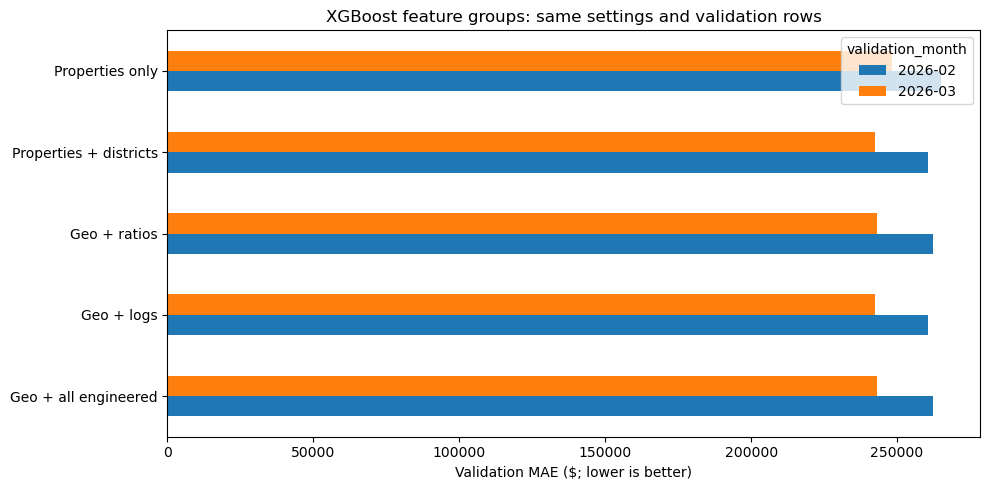

In [28]:
FOLLOWUP_ENGINEERED = ["PropertyAge", "BedBathRatio", "LivingAreaPerBedroom", "LogLivingArea", "LogLotSize"]
# Week 6's function uses this constant when replacing infinite derived values.
ENGINEERED_FEATURES = list(FOLLOWUP_ENGINEERED)
def engineer_property_features(frame, reference_year):
    """Return a copy; reference_year may be a scalar or an aligned Series."""
    result = frame.copy()
    years = pd.Series(reference_year, index=result.index, dtype="float64")
    built = pd.to_numeric(result["YearBuilt"], errors="coerce")
    area = pd.to_numeric(result["LivingArea"], errors="coerce")
    lot = pd.to_numeric(result["LotSizeSquareFeet"], errors="coerce")
    beds = pd.to_numeric(result["BedroomsTotal"], errors="coerce")
    baths = pd.to_numeric(result["BathroomsTotalInteger"], errors="coerce")
    age = years - built
    result["PropertyAgeNegativeFlag"] = age.lt(0)
    result["PropertyAge"] = age.where(age.ge(0))
    result["BedBathRatio"] = beds.where(beds.ge(0)) / baths.where(baths.gt(0))
    result["LivingAreaPerBedroom"] = area.where(area.gt(0)) / beds.where(beds.gt(0))
    result["LogLivingArea"] = np.log1p(area.where(area.gt(0)))
    result["LogLotSize"] = np.log1p(lot.where(lot.gt(0)))
    result[ENGINEERED_FEATURES] = result[ENGINEERED_FEATURES].replace([np.inf, -np.inf], np.nan)
    return result

followup_train = engineer_property_features(train_geo, train_geo["CloseDate"].dt.year)
assert followup_train.index.equals(train_geo.index)
assert not np.isinf(followup_train[FOLLOWUP_ENGINEERED].to_numpy()).any()
followup_features = {
    "Properties only": [c for c in FEATURES if c not in DISTRICT_FEATURES],
    "Properties + districts": list(FEATURES),
    "Geo + logs": FEATURES + ["LogLivingArea", "LogLotSize"],
    "Geo + ratios": FEATURES + ["BedBathRatio", "LivingAreaPerBedroom"],
    "Geo + all engineered": FEATURES + FOLLOWUP_ENGINEERED,
}
display(pd.DataFrame([{"feature_set": label, "predictor_count": len(columns), "predictors": ", ".join(columns)}
                      for label, columns in followup_features.items()]))

def build_followup_pipeline(estimator, training_rows, columns):
    numeric = [c for c in columns if c in NUMERIC_USED + FOLLOWUP_ENGINEERED and training_rows[c].notna().any()]
    categorical = [c for c in columns if c in CATEGORICAL_USED and training_rows[c].notna().any()]
    assert set(columns).issubset(set(NUMERIC_USED + FOLLOWUP_ENGINEERED + CATEGORICAL_USED))
    transforms = []
    if numeric:
        transforms.append(("numeric", Pipeline([
            ("impute", SimpleImputer(strategy="median", add_indicator=True)),
            ("scale", StandardScaler()),
        ]), numeric))
    if categorical:
        transforms.append(("categorical", Pipeline([
            ("impute", SimpleImputer(strategy="constant", fill_value="Missing")),
            ("encode", OneHotEncoder(handle_unknown="ignore", drop="first")),
        ]), categorical))
    return Pipeline([("preprocess", ColumnTransformer(transforms)), ("regression", clone(estimator))])

def fit_followup_fold(fit_rows, valid_rows, columns, parameters):
    assert fit_rows["CloseDate"].max() < valid_rows["CloseDate"].min()
    assert len(valid_rows) >= 2 and valid_rows[TARGET].nunique() > 1
    estimator = XGBRegressor(**{**XGB_FIXED, **parameters})
    fitted = build_followup_pipeline(estimator, fit_rows, columns)
    fitted.fit(fit_rows[columns], fit_rows[TARGET])
    fit_metrics = regression_metrics(fit_rows[TARGET], fitted.predict(fit_rows[columns]))
    valid_metrics = regression_metrics(valid_rows[TARGET], fitted.predict(valid_rows[columns]))
    metrics = {"train_mae_usd": fit_metrics["mae_usd"], "train_r2": fit_metrics["r2"],
               "validation_mae_usd": valid_metrics["mae_usd"],
               "validation_rmse_usd": valid_metrics["rmse_usd"], "validation_r2": valid_metrics["r2"],
               "r2_gap": fit_metrics["r2"] - valid_metrics["r2"],
               "train_rows": len(fit_rows), "validation_rows": len(valid_rows)}
    return fitted, metrics

followup_months = followup_train["CloseDate"].dt.to_period("M")
followup_rows = []
for validation_month in VALIDATION_MONTHS:
    fit_rows = followup_train.loc[followup_months.lt(validation_month)]
    valid_rows = followup_train.loc[followup_months.eq(validation_month)]
    for label, columns in followup_features.items():
        print(f"Feature study {validation_month}: {label}", flush=True)
        _, metrics = fit_followup_fold(fit_rows, valid_rows, columns, BEST_PARAMS)
        followup_rows.append({"validation_month": str(validation_month), "feature_set": label, **metrics})
followup_feature_results = pd.DataFrame(followup_rows)
followup_feature_summary = followup_feature_results.groupby("feature_set", sort=False).agg(
    mean_validation_mae_usd=("validation_mae_usd", "mean"),
    mean_validation_rmse_usd=("validation_rmse_usd", "mean"),
    mean_validation_r2=("validation_r2", "mean"), mean_train_r2=("train_r2", "mean"),
    mean_r2_gap=("r2_gap", "mean"),
)
geo_reference_mae = followup_feature_summary.loc["Properties + districts", "mean_validation_mae_usd"]
followup_feature_summary["mae_improvement_vs_geo_reference_usd"] = geo_reference_mae - followup_feature_summary["mean_validation_mae_usd"]
# Stable ordering favors earlier, simpler sets when scores tie exactly.
followup_feature_summary = followup_feature_summary.sort_values("mean_validation_mae_usd", kind="stable")
FOLLOWUP_FEATURE_SET = followup_feature_summary.index[0]
FOLLOWUP_COLUMNS = list(followup_features[FOLLOWUP_FEATURE_SET])
display(followup_feature_results.round(4))
display(followup_feature_summary.round(4))
print("Provisional feature candidate (reused validation only):", FOLLOWUP_FEATURE_SET)
ax = followup_feature_results.pivot(index="feature_set", columns="validation_month", values="validation_mae_usd").plot.barh(figsize=(10, 5))
ax.set(title="XGBoost feature groups: same settings and validation rows", xlabel="Validation MAE ($; lower is better)", ylabel="")
plt.tight_layout()
plt.show()


### Feature results

School districts lowered MAE in both months. Log-size features produced identical scores to properties plus districts. Ratios increased MAE in both months, and the full bundle matched the ratio-only results.

**Properties plus districts** is retained as the simplest configuration with the lowest mean validation MAE. The log transformations supply no measured benefit in this run, and property age adds no independent information alongside YearBuilt.


## 9. Complexity and generalization

Tuned XGBoost achieved training R² **0.9574** and April R² **0.7292**. The gap motivates checking model complexity, although changes between months may also contribute.

With features held fixed, the original settings are compared with depth-3 trees and stronger regularization through minimum child weight, L2 penalty, and row/column subsampling. Validation error determines whether a restriction is useful; a smaller training gap alone is insufficient.


Complexity check 2026-02: Original tuned settings
Complexity check 2026-02: Shallower depth=3


/opt/anaconda3/envs/myenv/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 1, 2, 3, 4] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


Complexity check 2026-02: Stronger regularization


/opt/anaconda3/envs/myenv/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 1, 2, 3, 4] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


Complexity check 2026-03: Original tuned settings


/opt/anaconda3/envs/myenv/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 1, 2, 3, 4] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


... (2 outputs left out)

Complexity check 2026-03: Stronger regularization


/opt/anaconda3/envs/myenv/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 1, 2, 3, 4] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/opt/anaconda3/envs/myenv/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 1, 2, 3, 4] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


,validation_month,configuration,train_mae_usd,train_r2,validation_mae_usd,validation_rmse_usd,validation_r2,r2_gap,train_rows,validation_rows
0,2026-02,Original tuned settings,132632.0677,0.9781,260507.7995,732859.9520,0.6964,0.2818,7473,8950
1,2026-02,Shallower depth=3,223695.9633,0.9130,294577.2515,743606.1513,0.6874,0.2256,7473,8950
2,2026-02,Stronger regularization,194846.3340,0.9239,278641.2670,730269.5639,0.6985,0.2254,7473,8950
3,2026-03,Original tuned settings,155782.4344,0.9621,242297.6004,670738.2684,0.7927,0.1694,16423,11551
4,2026-03,Shallower depth=3,237701.7893,0.8889,282049.0437,719041.2748,0.7618,0.1271,16423,11551
5,2026-03,Stronger regularization,203756.6145,0.9072,253971.0182,661320.1484,0.7985,0.1087,16423,11551


,mean_validation_mae_usd,mean_validation_rmse_usd,mean_validation_r2,mean_train_r2,mean_r2_gap
configuration,,,,,
Original tuned settings,251402.7000,701799.1102,0.7446,0.9701,0.2256
Stronger regularization,266306.1426,695794.8561,0.7485,0.9156,0.1670
Shallower depth=3,288313.1476,731323.7130,0.7246,0.9009,0.1763


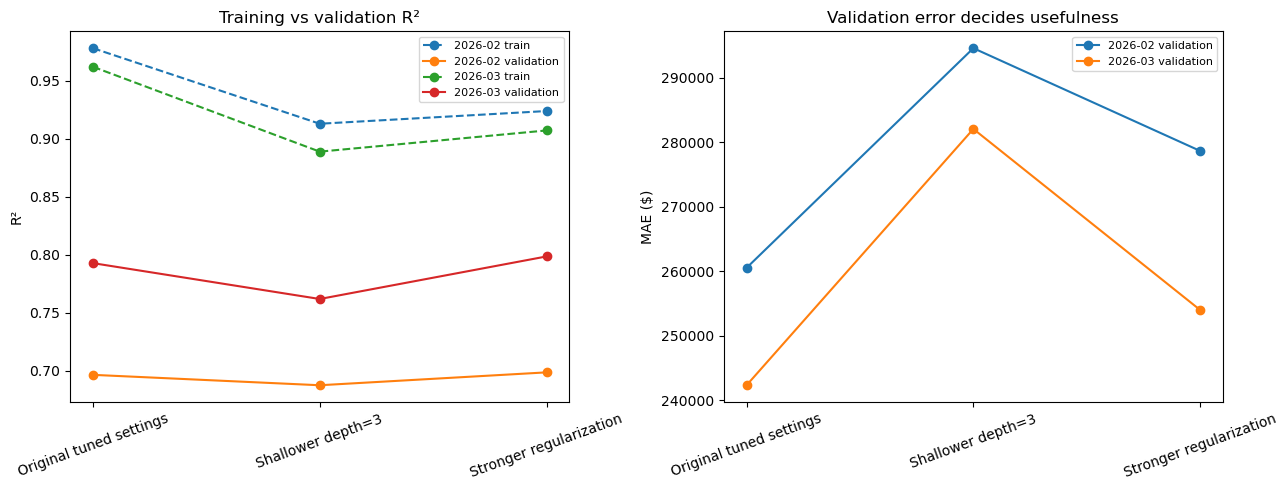

Provisional configuration: Original tuned settings
Do not assign the original April score to this follow-up candidate.


In [29]:
followup_controls = {
    "Original tuned settings": dict(BEST_PARAMS),
    "Shallower depth=3": {**BEST_PARAMS, "max_depth": 3},
    "Stronger regularization": {**BEST_PARAMS, "min_child_weight": 10,
                                 "reg_lambda": 10, "subsample": .8, "colsample_bytree": .8},
}
control_rows = []
followup_march_models = {}
for validation_month in VALIDATION_MONTHS:
    fit_rows = followup_train.loc[followup_months.lt(validation_month)]
    valid_rows = followup_train.loc[followup_months.eq(validation_month)]
    for label, parameters in followup_controls.items():
        print(f"Complexity check {validation_month}: {label}", flush=True)
        fitted, metrics = fit_followup_fold(fit_rows, valid_rows, FOLLOWUP_COLUMNS, parameters)
        control_rows.append({"validation_month": str(validation_month), "configuration": label, **metrics})
        if validation_month == max(VALIDATION_MONTHS):
            followup_march_models[label] = fitted
followup_control_results = pd.DataFrame(control_rows)
followup_control_summary = followup_control_results.groupby("configuration", sort=False).agg(
    mean_validation_mae_usd=("validation_mae_usd", "mean"),
    mean_validation_rmse_usd=("validation_rmse_usd", "mean"),
    mean_validation_r2=("validation_r2", "mean"), mean_train_r2=("train_r2", "mean"),
    mean_r2_gap=("r2_gap", "mean"),
).sort_values("mean_validation_mae_usd", kind="stable")
FOLLOWUP_CONFIGURATION = followup_control_summary.index[0]
importance_model = followup_march_models[FOLLOWUP_CONFIGURATION]
display(followup_control_results.round(4))
display(followup_control_summary.round(4))
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for month, group in followup_control_results.groupby("validation_month"):
    axes[0].plot(group["configuration"], group["train_r2"], marker="o", linestyle="--", label=f"{month} train")
    axes[0].plot(group["configuration"], group["validation_r2"], marker="o", label=f"{month} validation")
    axes[1].plot(group["configuration"], group["validation_mae_usd"], marker="o", label=f"{month} validation")
axes[0].set(title="Training vs validation R²", ylabel="R²")
axes[1].set(title="Validation error decides usefulness", ylabel="MAE ($)")
for ax in axes:
    ax.tick_params(axis="x", rotation=20)
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
print("Provisional configuration:", FOLLOWUP_CONFIGURATION)
print("Do not assign the original April score to this follow-up candidate.")


### Complexity results

Both restrictions reduced training fit and narrowed the R² gap. Stronger regularization increased mean validation MAE by **$14,903 (5.93%)**; depth-3 trees increased it by **$36,910 (14.68%)**.

Stronger regularization improved validation RMSE and R², but worsened the primary MAE metric in both months. The original tuned settings are retained. These results document the generalization tradeoff without establishing that overfitting has been eliminated.


## 10. Validation feature importance

Permutation importance is computed on a reproducible sample of **3,000 March properties** using the model trained on January–February. The increase in MAE after shuffling a feature family measures model dependence on that information. Coordinates and district codes are each shuffled jointly; any derived features are recomputed from their source values.

Bars show mean MAE increases across five shuffles; error bars show shuffle variability, not confidence intervals. Correlated predictors may substitute for one another. Importance is model-specific, noncausal, and nonadditive. Parenthetical labels identify available derived-feature families; the selected model contains properties plus districts.


/opt/anaconda3/envs/myenv/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 1, 2, 3, 4] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/opt/anaconda3/envs/myenv/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 1, 2, 3, 4] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/opt/anaconda3/envs/myenv/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 1, 2, 3, 4] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/opt/anaconda3/envs/myenv/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 1, 2, 3, 4] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/opt

,feature_family,mae_increase_usd,shuffle_std_usd,repeats
7,Coordinates (latitude + longitude),291424.49,5173.69,5
0,Living area (including derived features),231708.50,3028.69,5
10,School districts (3 codes),68263.71,2314.51,5
3,Bathrooms (including bed/bath ratio),67626.84,2694.72,5
8,City,60374.99,1865.76,5
9,ZIP code,28040.17,2811.85,5
4,Year built (including property age),18313.90,1736.04,5
1,Lot size (including log lot size),16118.11,1384.47,5
2,Bedrooms (including derived ratios),12537.89,521.28,5
5,Garage spaces,7908.87,947.99,5


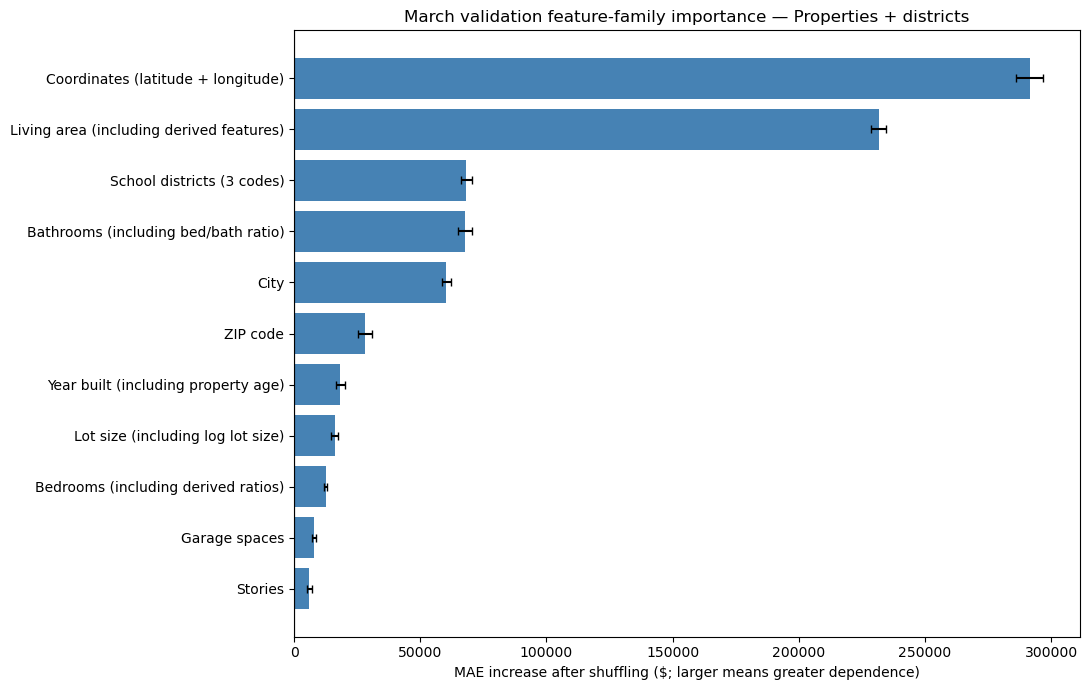

Importance model: Original tuned settings Sample rows: 3000 Unshuffled sample MAE: 232979.72


In [30]:
importance_source = train_geo.loc[
    train_geo["CloseDate"].dt.to_period("M").eq(max(VALIDATION_MONTHS))
].sample(n=min(3000, int(followup_months.eq(max(VALIDATION_MONTHS)).sum())), random_state=42).copy()
assert importance_source["CloseDate"].dt.to_period("M").eq(max(VALIDATION_MONTHS)).all()
importance_groups = {
    "Living area (including derived features)": ["LivingArea"],
    "Lot size (including log lot size)": ["LotSizeSquareFeet"],
    "Bedrooms (including derived ratios)": ["BedroomsTotal"],
    "Bathrooms (including bed/bath ratio)": ["BathroomsTotalInteger"],
    "Year built (including property age)": ["YearBuilt"],
    "Garage spaces": ["GarageSpaces"], "Stories": ["Stories"],
    "Coordinates (latitude + longitude)": ["Latitude", "Longitude"],
    "City": ["City"], "ZIP code": ["PostalCode"],
    "School districts (3 codes)": list(DISTRICT_FEATURES),
}
importance_groups = {label: columns for label, columns in importance_groups.items()
                     if any(c in FOLLOWUP_COLUMNS for c in columns)}
importance_actual = importance_source[TARGET].to_numpy()
importance_input = engineer_property_features(importance_source, importance_source["CloseDate"].dt.year)
importance_baseline_mae = mean_absolute_error(importance_actual, importance_model.predict(importance_input[FOLLOWUP_COLUMNS]))
importance_rng = np.random.default_rng(42)
importance_rows = []
for label, columns in importance_groups.items():
    increases = []
    for repeat in range(5):
        shuffled = importance_source.copy()
        order = importance_rng.permutation(len(shuffled))
        # One permutation for a family preserves its internal category/coordinate combinations.
        shuffled.loc[:, columns] = importance_source.iloc[order][columns].to_numpy()
        shuffled_input = engineer_property_features(shuffled, shuffled["CloseDate"].dt.year)
        shuffled_mae = mean_absolute_error(importance_actual, importance_model.predict(shuffled_input[FOLLOWUP_COLUMNS]))
        increases.append(float(shuffled_mae - importance_baseline_mae))
    importance_rows.append({"feature_family": label, "mae_increase_usd": np.mean(increases),
                            "shuffle_std_usd": np.std(increases), "repeats": len(increases)})
feature_family_importance = pd.DataFrame(importance_rows).sort_values("mae_increase_usd")
display(feature_family_importance.sort_values("mae_increase_usd", ascending=False).round(2))
fig, ax = plt.subplots(figsize=(11, 7))
ax.barh(feature_family_importance["feature_family"], feature_family_importance["mae_increase_usd"],
        xerr=feature_family_importance["shuffle_std_usd"], color="steelblue", capsize=3)
ax.axvline(0, color="black", linewidth=.8)
ax.set(title=f"March validation feature-family importance — {FOLLOWUP_FEATURE_SET}",
       xlabel="MAE increase after shuffling ($; larger means greater dependence)")
fig.tight_layout()
plt.show()
print("Importance model:", FOLLOWUP_CONFIGURATION, "Sample rows:", len(importance_source),
      "Unshuffled sample MAE:", round(importance_baseline_mae, 2))


### Importance results

Coordinates and living area had the largest permutation effects. District membership ranked third, close to bathrooms. This supports the contribution of geographic information and house size to the fitted model.

Permutation importance measures reliance on existing inputs. The preceding feature comparison separately measures whether additional representations improve validation performance.


## 11. Conclusions

**Feature selection.** Districts reduced mean monthly XGBoost validation MAE by **$5,266**, from **$256,669 to $251,403**, with improvements in both months. Logs produced identical scores. Ratios and the full bundle increased mean MAE to **$252,634**. Properties plus districts is retained.

**Complexity.** Stronger regularization reduced the mean training–validation R² gap from **0.2256 to 0.1670**, but increased mean MAE to **$266,306**. It improved mean RMSE from **$701,799 to $695,795**. The original tuned settings remain preferable for MAE.

**Model comparison.** Random Forest achieved the lowest April MAE (**$241,295**). Tuned XGBoost achieved the lowest April RMSE (**$811,825**) and highest R² (**0.7292**), with MAE **$251,189**. Model choice depends on whether average absolute error or large-error penalties are the priority; MAE remains the primary criterion in this analysis.

**Predictive information.** Coordinates and living area had the largest permutation effects, followed by district membership and bathrooms. These rankings describe dependence in the fitted model rather than causal effects or additive accuracy gains.

**Limitations and next steps.** April was previously inspected, and later feature/regularization choices reused historical validation months. A future uninspected period is needed for stronger confirmation. Repeated physical addresses, spatial similarity, boundary vintage, and field availability for off-market properties also require consideration. Week 8 will expand percentage-error metrics and price-band evaluation.

References: [XGBoost parameters](https://xgboost.readthedocs.io/en/stable/parameter.html), [permutation importance](https://scikit-learn.org/stable/modules/permutation_importance.html), [regression metrics](https://scikit-learn.org/stable/modules/model_evaluation.html#regression-metrics).


## 12. Results export

The exports record the original test comparison, supporting diagnostics, and subsequent validation experiments. Reports include feature definitions, selected settings, package versions, and input/boundary hashes. Run the diagnostic cells before the final exports, then save the notebook with its outputs.


In [31]:
# Append aggregate diagnostics to the existing reproducibility report.
# Run after the error-diagnostic cell; no refitting is needed.
report["error_diagnostics"] = json.loads(error_diagnostics.to_json(orient="records"))
report["price_band_metrics"] = json.loads(price_band_metrics.to_json(orient="records"))
report["price_band_training_thresholds"] = price_cuts.tolist()
report["training_median_reference_test_metrics"] = median_reference_metrics
report["primary_metric_conclusion"] = "Random Forest has lower April MAE; tuned XGBoost has lower RMSE and higher R²."
(output_dir / "advanced_model_results.json").write_text(json.dumps(report, indent=2) + "\n")
print("Updated aggregate report:", output_dir / "advanced_model_results.json")


Updated aggregate report: /Users/daira/IDX-Exchange-Data-Science/artifacts/week7/advanced_model_results.json


In [32]:
followup_report = {
    "generated_utc": datetime.now(timezone.utc).isoformat(),
    "input_sha256": input_sha256, "boundary_sha256": boundary_metadata["sha256"],
    "package_versions": package_versions,
    "status": "Completed exploratory validation follow-up after April inspection; no new test scores",
    "reviewed_findings": {
        "features": "Properties plus districts retained; logs tie, ratios worsen MAE in both months.",
        "complexity": "Original tuned settings retain lowest MAE; stronger regularization improves RMSE but worsens MAE.",
        "importance": "Coordinates and living area rank highest, followed by districts and bathrooms."
    },
    "fixed_feature_experiment_parameters": BEST_PARAMS,
    "feature_sets": followup_features,
    "feature_results": json.loads(followup_feature_results.to_json(orient="records")),
    "feature_summary": json.loads(followup_feature_summary.reset_index().to_json(orient="records")),
    "control_parameters": followup_controls,
    "control_results": json.loads(followup_control_results.to_json(orient="records")),
    "control_summary": json.loads(followup_control_summary.reset_index().to_json(orient="records")),
    "provisional_feature_set": FOLLOWUP_FEATURE_SET, "provisional_configuration": FOLLOWUP_CONFIGURATION,
    "permutation_feature_families": importance_groups,
    "permutation_importance": json.loads(feature_family_importance.to_json(orient="records")),
    "importance_validation_month": str(max(VALIDATION_MONTHS)),
    "importance_sample_rows": len(importance_source), "importance_baseline_mae_usd": importance_baseline_mae,
}
followup_output_dir = project_root / "artifacts" / "week7"
followup_output_dir.mkdir(parents=True, exist_ok=True)
(followup_output_dir / "feature_and_generalization_review.json").write_text(json.dumps(followup_report, indent=2) + "\n")
print("Saved follow-up results:", followup_output_dir / "feature_and_generalization_review.json")


Saved follow-up results: /Users/daira/IDX-Exchange-Data-Science/artifacts/week7/feature_and_generalization_review.json
